### Feature Engineering

In addition to features identified by Yera, this notebook includes a few additional interaction terms:

- NFLOOR_CEILING_HEIGHT: NFLOOR_NUMERIC * FLCEILHT. A proxy for building height (ie num. of floors * height of each floor). This is capped by the response ranges given for ceiling heights and the condensed floor responses for buildings with 10 or more floors (indicated by NFLOOR_CEILING_HEIGHT__clipped).

- NFLOOR_NUMERIC: Converts the categorical NFLOOR response to numeric in order to estimate the above

- HDD65_CDD65: Interaction term for heating degree and cooling degree days. These terms have a strong linear association.

- COOLP_HEATP: Interaction term for percent cooled and percent heated. Moderate linear association. Missing values flagged with COOLP_HEATP__missing.

- SQFT_WKHRS: Interaction term for area and working areas. These have a modest linear association. 

- CENDIV_PUBCLIM: A categorical combination for census division and climate zone. Generates a unique dummy variable for each combination of the individual terms in training. Cramer's V shows strong linear association between these two terms, which reflects the natural link between geography and climate. Some climate zones are withheld in the response data -- those responses are still included in the combined dummy terms (eg. withheld,code_1)

NFLOOR_CEILING_HEIGHT and CENDIV_PUBCLIM are the most interesting and intuitive interactions, but their utility may be limited by missing or masked response data. The others reflect strong-to-moderate linear associations. We can experiment with including/excluding these features in the models to see if there is any meaningful benefit. 

In [887]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import statsmodels.api as sm

cwd = Path.cwd()
root = cwd.parent

# Data
raw = pd.read_csv(root / 'cbecs2018_notebook/data/raw/cbecs2018_final_public.csv')

# Features
numeric = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
categorical = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP',
                          'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
source_features = numeric + categorical

processed_df = pd.read_csv(str(root / 'cbecs2018_processed.csv'))

# Training rows
split_membership = pd.read_csv(str(root / 'cbecs2018_notebook/data/processed/split_membership.csv'))

In [888]:
def preprocess(
        raw: pd.DataFrame, 
        numeric_features: list = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP'],
        categorical_features: list = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP', 'GLSSPC', 'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
        ):
    """Removes rows without energy targets. Splits data into train and test. Extracts identified features. Recodes categoricals.
    Returns data and train/val/test splits."""
    SEED = 42
    missing_target = raw.MFBTU.isna()
    assert raw.loc[missing_target, 'ZMFBTU'].eq(9).all()
    data = raw.loc[~missing_target].sort_values('PUBID').copy()
    excluded = raw.loc[missing_target, ['PUBID', 'ZMFBTU']].copy()
    excluded['reason'] = 'MFBTU not applicable' 
    assert data.MFBTU.ge(0).all() and np.isfinite(data.MFBTU).all()
    assert data.FINALWT.gt(0).all()
    fit_rows, held_out = train_test_split(data.index, test_size=0.30, random_state=SEED)
    validation_rows, test_rows = train_test_split(held_out, test_size=0.50, random_state=SEED)
    splits = {'train': sorted(fit_rows), 'validation': sorted(validation_rows), 'test': sorted(test_rows)}
    clean = data[numeric_features + categorical_features + ['PUBID','MFBTU']].copy()

    return clean, splits

In [889]:
def clean_inputs(frame):
    source = frame.reindex(columns=source_features).copy()
    flags = source.isna().astype(float).add_suffix('__is_missing')
    numbers = source[numeric].apply(pd.to_numeric, errors='raise').astype(float)
    flags['SQFT__above_1m'] = numbers.SQFT.gt(1_000_000).astype(float)
    flags['NWKER__5000_or_more'] = numbers.NWKER.ge(5_000).astype(float)
    flags['FLCEILHT__above_50'] = numbers.FLCEILHT.gt(50).astype(float)
    numbers['SQFT'] = numbers.SQFT.clip(upper=1_000_000)
    numbers['NWKER'] = numbers.NWKER.clip(upper=5_000)
    numbers['FLCEILHT'] = numbers.FLCEILHT.clip(upper=50)
    groups = pd.DataFrame(index=source.index)
    for col in categorical:
        groups[col] = source[col].map(lambda v: 'missing' if pd.isna(v) else f'code_{int(v)}')
    groups['NFLOOR'] = groups.NFLOOR.replace({'code_994': '10_to_14', 'code_995': '15_or_more'})
    groups['PUBCLIM'] = groups.PUBCLIM.replace({'code_7': 'withheld'})
    return numbers, groups, flags

In [890]:
data, splits = preprocess(raw)
numbers, groups, flags = clean_inputs(data)
clean = pd.concat([numbers, groups, flags], axis=1)
df_train = clean.loc[splits['train']]

assert numbers.SQFT.le(1_000_000).all() and numbers.NWKER.le(5_000).all()
display(flags[['SQFT__above_1m', 'NWKER__5000_or_more']].sum().rename('Flagged buildings').to_frame())

,Flagged buildings
SQFT__above_1m,125.0
NWKER__5000_or_more,15.0


In [891]:
# Numeric spearman correlations
df_train[numeric].corr('pearson')

,SQFT,FLCEILHT,WKHRS,NWKER,MONUSE,HDD65,CDD65,HEATP,COOLP,OCCUPYP
SQFT,1.000000,0.057061,0.304845,0.688181,0.082180,-0.013305,-0.018891,0.020957,0.040990,-0.049427
FLCEILHT,0.057061,1.000000,-0.036041,-0.073597,0.049196,-0.045803,0.019319,-0.205045,-0.319713,-0.038647
WKHRS,0.304845,-0.036041,1.000000,0.177872,0.178839,0.003856,-0.005155,0.047712,0.142038,0.022730
NWKER,0.688181,-0.073597,0.177872,1.000000,0.078328,-0.006699,-0.018295,0.056925,0.122922,0.031121
MONUSE,0.082180,0.049196,0.178839,0.078328,1.000000,-0.022607,0.003481,-0.018681,0.028816,0.077459
HDD65,-0.013305,-0.045803,0.003856,-0.006699,-0.022607,1.000000,-0.711517,0.197809,-0.054995,-0.005394
CDD65,-0.018891,0.019319,-0.005155,-0.018295,0.003481,-0.711517,1.000000,-0.122563,0.089407,-0.033197
HEATP,0.020957,-0.205045,0.047712,0.056925,-0.018681,0.197809,-0.122563,1.000000,0.480767,0.235487
COOLP,0.040990,-0.319713,0.142038,0.122922,0.028816,-0.054995,0.089407,0.480767,1.000000,0.270549
OCCUPYP,-0.049427,-0.038647,0.022730,0.031121,0.077459,-0.005394,-0.033197,0.235487,0.270549,1.000000


Some of the strong associations:
- HDD65 and CDD65
- COOLP and HEATP
- WKHRS and SQFT

These are reasonable candidates for feature interaction terms.


Spearman Corr. for HDD65 and CDD65 (heating/cooling degree days) = -0.7386
Spearman Corr. for COOLP and HEATP (heating/cooling percent of days) = 0.4893
Spearman Corr. for WKHRS and SQFT (working hours and area) = 0.3881



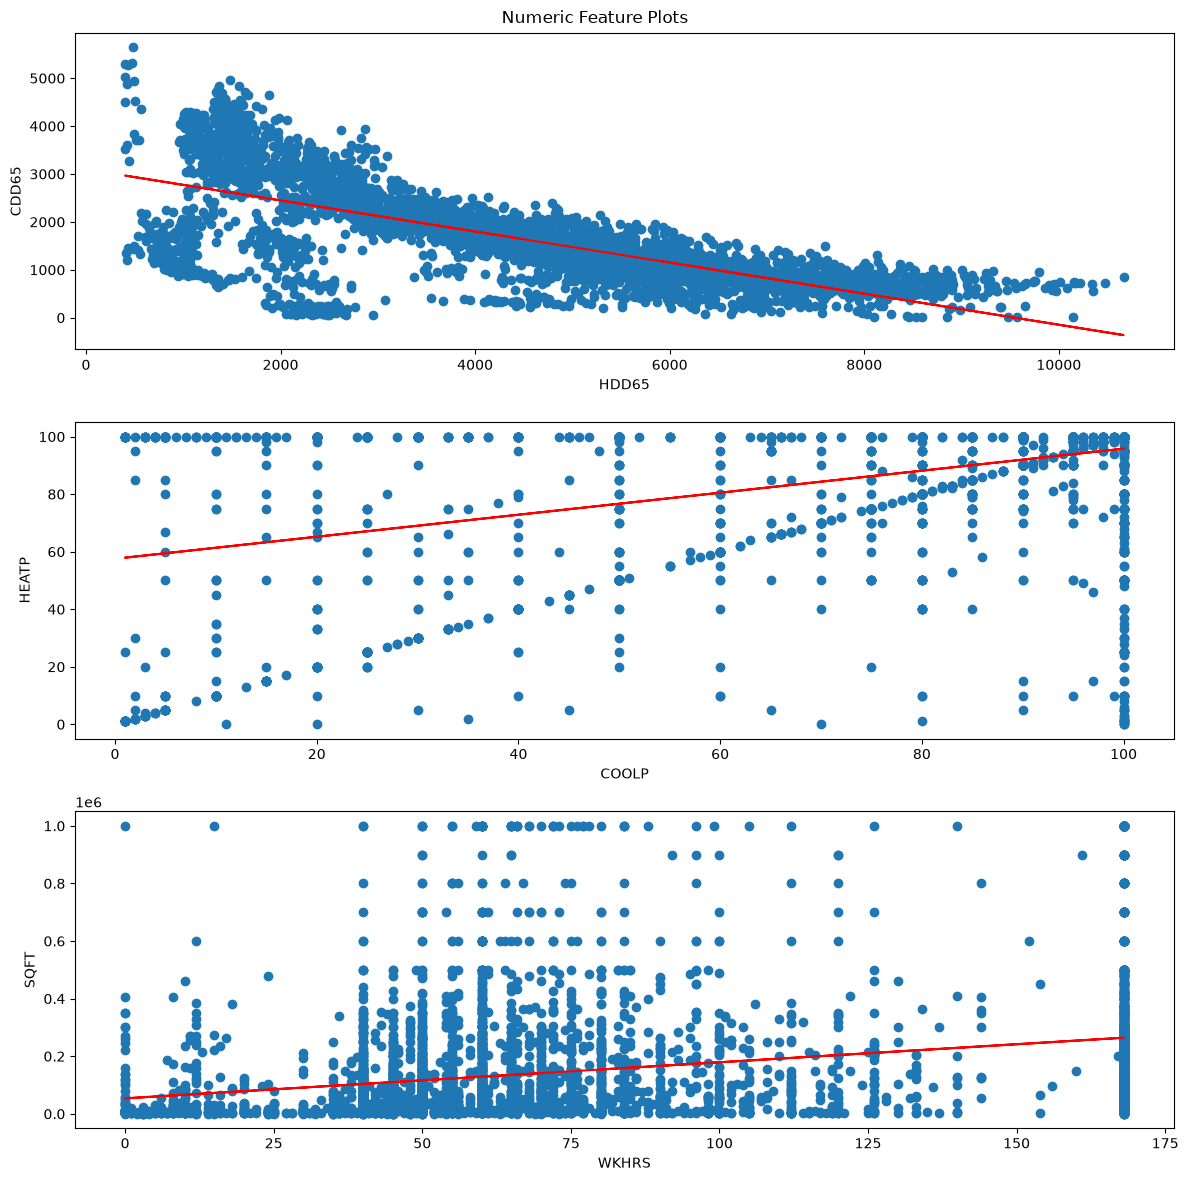

In [892]:
feature_pairs = ['HDD65', 'CDD65'], ['COOLP','HEATP'], ['WKHRS','SQFT']

fig, axes = plt.subplots(3,1, figsize=(12,12))
for pair, ax in zip(feature_pairs, axes):
    plot_df = df_train.dropna(subset=[pair[0],pair[1]])
    x, y = plot_df[pair[0]].to_numpy(), plot_df[pair[1]].to_numpy()
    ax.scatter(x=x, y=y)
    m, b = np.polyfit(x, y, 1)
    ax.plot(x, b + m * x, '-', color='red')    
    ax.set_xlabel(pair[0])
    ax.set_ylabel(pair[1])
plt.suptitle('Numeric Feature Plots')
plt.tight_layout()

print(f"""
Spearman Corr. for HDD65 and CDD65 (heating/cooling degree days) = {round(df_train[feature_pairs[0]].corr('spearman').to_numpy()[1,0], 4)}
Spearman Corr. for COOLP and HEATP (heating/cooling percent of days) = {round(df_train[feature_pairs[1]].corr('spearman').to_numpy()[1,0], 4)}
Spearman Corr. for WKHRS and SQFT (working hours and area) = {round(df_train[feature_pairs[2]].corr('spearman').to_numpy()[1,0], 4)}
""")

# Reasonably strong/modest associations between these variables. Visual evidence of linear relationships. 

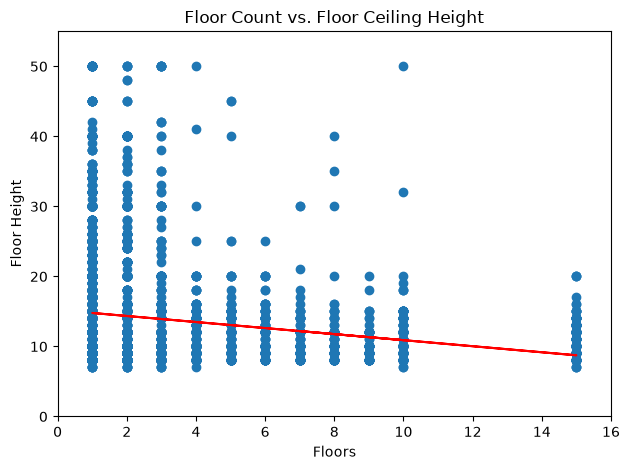

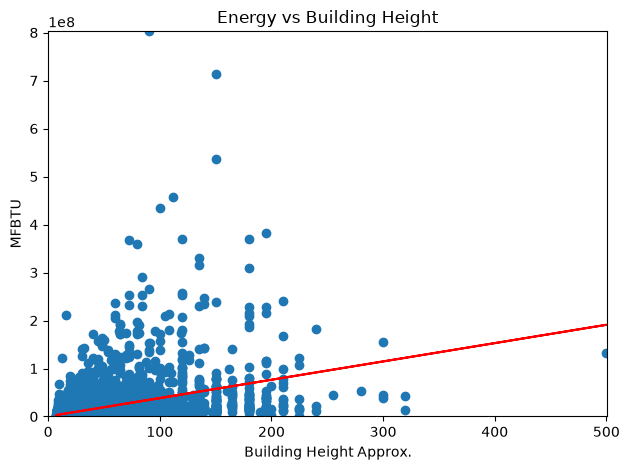

Spearman Corr. for Floor Count and Ceiling Height = -0.2519
Spearman Corr. for Building Height and Energy = 0.602
Spearman Corr. for Building Height and Energy (Clipped) = 0.602


In [893]:
# Testing association between floor count and floor-ceiling height

# Numeric floor count (floor at 10 for responses between 10 and 15, floor at 15 for all 15 or abvoe)
df_train['NFLOOR_NUMERIC'] = data.loc[splits['train']]['NFLOOR']
df_train['NFLOOR_NUMERIC'] = np.where(
    df_train['NFLOOR_NUMERIC'] == 994, 10, 
        np.where(df_train['NFLOOR_NUMERIC'] == 995, 15, df_train['NFLOOR_NUMERIC'])
    )

# Floor vs Ceiling Height
x=df_train['NFLOOR_NUMERIC'].to_numpy()
y=df_train['FLCEILHT'].to_numpy()
plt.scatter(x,y)
m, b = np.polyfit(df_train['NFLOOR_NUMERIC'].to_numpy(), df_train['FLCEILHT'].to_numpy(), 1)
plt.plot(x, b + m * x, '-', color='red')
plt.xlim(0, max(x)+1)  
plt.ylim(0, max(y)+5)
plt.xlabel('Floors')
plt.ylabel('Floor Height')
plt.title('Floor Count vs. Floor Ceiling Height')
plt.tight_layout()
plt.show()

# Testing association between approximated building height (floor-ceiling height * floor count) and energy consumption
# Floor * Ceiling Height vs MFBTU
df_train['NFLOOR_CEILING_HEIGHT'] = df_train['NFLOOR_NUMERIC'] * df_train['FLCEILHT']
x=df_train['NFLOOR_CEILING_HEIGHT'].to_numpy()
y=data.loc[splits['train']]['MFBTU'].to_numpy()
plt.scatter(x=x, y=y)
m, b = np.polyfit(x, y, 1)
plt.plot(x, b + m * x, '-', color='red')
plt.xlim(0, max(x)+1)  
plt.ylim(0, max(y)+5)
plt.xlabel('Building Height Approx.')
plt.ylabel('MFBTU')
plt.title('Energy vs Building Height')
plt.tight_layout()
plt.show()

print(f"Spearman Corr. for Floor Count and Ceiling Height = {round(df_train[['FLCEILHT','NFLOOR_NUMERIC']].corr('spearman').to_numpy()[1,0], 4)}")
print(f"Spearman Corr. for Building Height and Energy = {round(pd.concat([df_train[['NFLOOR_CEILING_HEIGHT']], data.loc[splits['train']]['MFBTU']],axis=1).corr('spearman').to_numpy()[1,0], 4)}")
print(f"Spearman Corr. for Building Height and Energy (Clipped) = {round(pd.concat([df_train[['NFLOOR_CEILING_HEIGHT']], data.loc[splits['train']]['MFBTU']],axis=1).corr('spearman').to_numpy()[1,0], 4)}")

In [894]:
# Testing likelihood that all observed census divisions and climate zone observations are equally likely
from scipy.stats import chisquare, chi2_contingency

chi_2_result = chisquare(df_train[['PUBCLIM','CENDIV']].value_counts())
print(f"""Chi-squared test on Climate Zone and Census Division
Test statistic = {chi_2_result[0]}
p-value = {chi_2_result[1]}""")

# Cramer's V test of association between census divisions and climate zones
def cramerV(label,x):
    confusion_matrix = pd.crosstab(label, x)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    r,k = confusion_matrix.shape
    phi2 = chi2/n
    phi2corr = max(0,phi2-((k-1)*(r-1))/(n-1))
    rcorr = r - ((r - 1) ** 2) / ( n - 1 )
    kcorr = k - ((k - 1) ** 2) / ( n - 1 )
    v = np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))
    return v

print(f"Cramer's V Corr. = {cramerV(df_train['PUBCLIM'], df_train['CENDIV'])}")

# Appears to be strong association between census division and climate zone, which is intuitive. Reasonable justification to include in the model.

# Cramer's V code citation: 
# https://medium.com/@manindersingh120996/understanding-categorical-correlations-with-chi-square-test-and-cramers-v-a54fe153b1d6

Chi-squared test on Climate Zone and Census Division
Test statistic = 3626.747358957069
p-value = 0.0
Cramer's V Corr. = 0.4263481497322317


In [895]:
# Interactions
def interaction_features(numbers:pd.DataFrame, groups:pd.DataFrame, flags:pd.DataFrame) -> tuple(pd.DataFrame):
    numbers, groups, flags = numbers.copy(), groups.copy(), flags.copy()
    # Census division and climate zone
    groups['CENDIV_PUBCLIM'] = groups['CENDIV'].astype('str').str.cat(groups['PUBCLIM'].astype('str'), sep=',').astype('category')
    # Floor number and ceiling height
    numbers['NFLOOR_NUMERIC'] = data['NFLOOR']
    numbers['NFLOOR_NUMERIC'] = np.where(
        numbers['NFLOOR_NUMERIC'] == 994, 10, 
            np.where(numbers['NFLOOR_NUMERIC'] == 995, 15, numbers['NFLOOR_NUMERIC'])
        )
    numbers['NFLOOR_CEILING_HEIGHT'] = numbers['NFLOOR_NUMERIC'] * numbers['FLCEILHT']
    flags['NFLOOR_CEILING_HEIGHT__clipped'] = np.where(numbers['FLCEILHT'] == 995, 1, np.where(groups['NFLOOR'].isin(['10_to_14','15_or_more']), 1, 0))
    # Heating degree days and cooling degree days
    numbers['HDD65_CDD65'] = numbers['HDD65'] * numbers['CDD65']
    # Cooling percent and heating percent
    numbers['COOLP_HEATP'] = numbers['COOLP'] * numbers['HEATP']
    flags['COOLP_HEATP__missing'] = pd.concat((flags.HEATP__is_missing, flags.COOLP__is_missing), axis=1).max(axis=1)
    # Work hours and SQFT (area)
    numbers['SQFT_WKHRS'] = numbers['SQFT'] * numbers['WKHRS']

    return numbers[['NFLOOR_NUMERIC','NFLOOR_CEILING_HEIGHT','HDD65_CDD65','COOLP_HEATP','SQFT_WKHRS']], groups[['CENDIV_PUBCLIM']], flags[['NFLOOR_CEILING_HEIGHT__clipped','COOLP_HEATP__missing']]

In [896]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

extra_num_features = ['NFLOOR_NUMERIC','NFLOOR_CEILING_HEIGHT','HDD65_CDD65','COOLP_HEATP','SQFT_WKHRS']
eng_numbers, eng_groups, eng_flags = interaction_features(numbers, groups, flags)

# one hot encoding CENDIV_PUBCLIM
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=float)
encoder.fit(eng_groups.loc[splits['train']])
columns = [f'CENDIV_PUBCLIM_{c}' for c in encoder.categories_[0]]
encoded_data = pd.DataFrame(encoder.transform(eng_groups), index=eng_groups.index, columns=columns)

# impute missing values for COOLP_HEATP
imputer = SimpleImputer(strategy='median').fit(eng_numbers.loc[splits['train']])
eng_numbers = pd.DataFrame(imputer.transform(eng_numbers), index=data.index, columns=extra_num_features)

# combining engineered features
new_features = pd.concat([data[['PUBID']], encoded_data, eng_numbers, eng_flags], axis=1)

In [897]:
combined = processed_df.merge(
    new_features,
    on='PUBID',
    how='inner')

assert combined.shape[0] == processed_df.shape[0] == new_features.shape[0]
assert combined.PUBID.to_list() == processed_df.PUBID.to_list()

for c in combined.columns:
    assert ~combined[c].isnull().any() and ~combined[c].isna().any()

for split in split_membership.split.unique():
    pubid_a = split_membership[split_membership['split']==split]['PUBID'].to_numpy()
    pubid_b = combined[combined['split']==split]['PUBID'].to_numpy()
    assert np.array_equal(pubid_a, pubid_b)

combined.to_csv(str(cwd / 'processed_added_features.csv'))